<a href="https://colab.research.google.com/github/ShahSalar/python-data-exploration/blob/main/Sepehr_Kermanshah_regression_first_run.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CPSC 375 Classwork - Linear Regression

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ProfAvery/cpsc375-classwork/blob/main/regression.ipynb)

- *Manager*:
- *Recorder*:
- *Presenter*:
- *Timekeeper*:

*Note*: On Google Colab, run the following code cell to download the `cpsc375` module before trying to `import`:

In [18]:
!mkdir -p ./cpsc375 && wget --quiet --timestamping https://raw.githubusercontent.com/ProfAvery/cpsc375-classwork/refs/heads/main/cpsc375/__init__.py --output-document=./cpsc375/__init__.py

In [19]:
from cpsc375 import *

## Part 1 - Slide 8

Consider the problem of estimating Height given Weight and Age
* What are some linear models for this?
* What are some nonlinear models for this?


**Linear models**:
- Height = b0 + b1 * Weight
- Height = b0 + b1 * Age
- Height = b0 + b1 * Weight + b2 * Age

**Nonlinear models**:
- Quadratic: Height = b0 + b1 * Age + b2 * Age^2
- Log: Height = b0 + b1 * log(Weight) + b2 * log(Age)
- Interaction: Height = b0 + b1 * Weight + b2 * Age + b3 * (Weight * Age)
- Growth curve that levels off with age: Height = a * (1 − e ^ (−b * Age))

## Part 2 - Slide 11

How does Petal.Length change with Petal.Width?
* Which is the dependent variable? Which is the explanatory/independent variable?
* Draw a scatterplot
* Draw *any* straight line that fits the data well
  - Use `geom_abline()`


In [20]:
?geom_abline


In [21]:
iris = sm.datasets.get_rdataset('iris').data

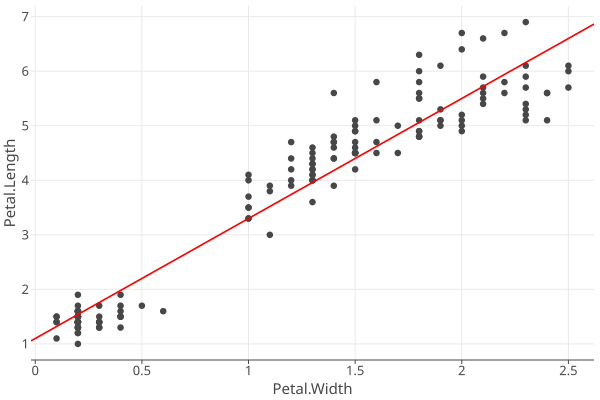

In [22]:
(ggplot(data=iris)
 + geom_point(aes(x='Petal.Width', y='Petal.Length'))
 + geom_abline(slope=2.2, intercept=1.1, color='red'))

## Part 3 - Slide 22

Consider the “Auto MPG” dataset which “concerns city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multivalued discrete and 5 continuous attributes.” The goal is to model mpg given engine displacement.


In [23]:
X = auto_mpg.data.original[["displacement"]]
y = auto_mpg.data.original["mpg"]


* Which is the dependent variable? Which is the independent variable?

* Plot mpg vs. displacement (code, plot)


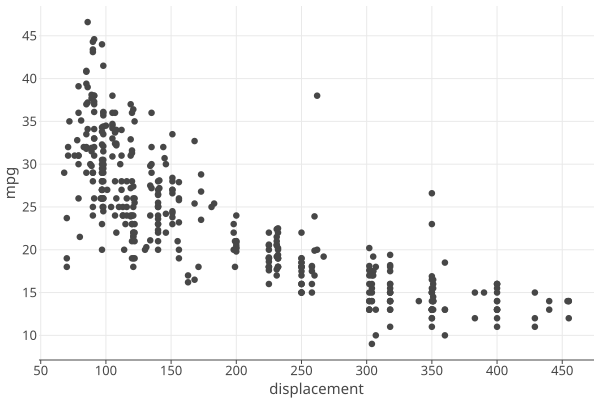

In [24]:
(
    ggplot(data=auto_mpg.data.original)
    + geom_point(mapping=aes(x='displacement', y='mpg'))
)

Overlay best fit line over the dataset (code, plot)


[np.float64(35.17475015429319), np.float64(-0.06028240546881721)]


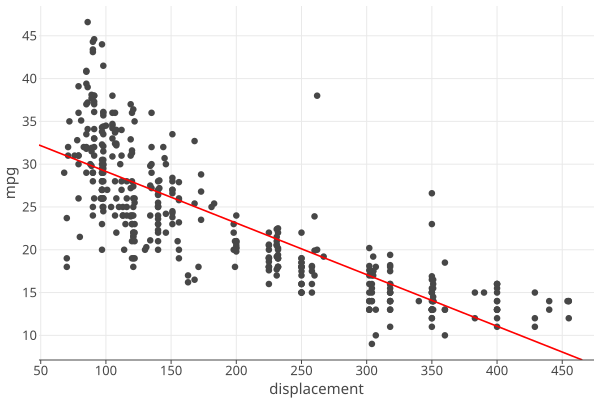

In [25]:
m = LinearRegression()
m.fit(X, y)
cf = [m.intercept_, *m.coef_]
print(cf)

(
    ggplot(data=auto_mpg.data.original)
    + geom_point(mapping=aes(x='displacement', y='mpg'))
    + geom_abline(slope=cf[1], intercept=cf[0], color='red')
)

## Part 4 - Slide 35

Which rows of iris are outliers based on the Petal.Width~Petal.Length model?


In [26]:
X = iris[['Petal.Length']]
y = iris['Petal.Width']

model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
residuals = y - y_pred

irisStdRes = iris.assign(rstd=residuals / residuals.std())

irisStdRes[(irisStdRes['rstd'] > 2) | (irisStdRes['rstd'] < -2)]

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species,rstd
107,7.3,2.9,6.3,1.8,virginica,-2.216740
114,5.8,2.8,5.1,2.4,virginica,3.123194
115,6.4,3.2,5.3,2.3,virginica,2.233205
122,7.7,2.8,6.7,2.0,virginica,-2.052992
129,7.2,3.0,5.8,1.6,virginica,-2.178460
134,6.1,2.6,5.6,1.4,virginica,-2.746266
136,6.3,3.4,5.6,2.4,virginica,2.113050
140,6.7,3.1,5.6,2.4,virginica,2.113050
141,6.9,3.1,5.1,2.3,virginica,2.637262
144,6.7,3.3,5.7,2.5,virginica,2.396953


## Part 5 - Slide 41

Consider the `auto_mpg.data.original` dataset

> The goal is to model mpg given engine displacement

Include the confidence intervals of the predictions below:

* Predict the mpg of a car with engine displacement=250


In [27]:
mod_displ = sm.formula.ols('mpg ~ displacement', data=auto_mpg.data.original)
results = mod_displ.fit()

predx = pd.DataFrame({'displacement': [250]})
predictions = results.get_prediction(predx)

predictions.summary_frame(alpha=0.05) \
    .filter(['mean', 'mean_ci_lower', 'mean_ci_upper'])

,mean,mean_ci_lower,mean_ci_upper
0,20.104149,19.58251,20.625787


* Predict the mpg of a car with engine displacement=600


In [28]:
predx = pd.DataFrame({'displacement': [600]})
predictions = results.get_prediction(predx)

predictions.summary_frame(alpha=0.05) \
    .filter(['mean', 'mean_ci_lower', 'mean_ci_upper'])

,mean,mean_ci_lower,mean_ci_upper
0,-0.994693,-2.841999,0.852613


In which prediction (for displ=250 or displ=600) are you more confident?


More confident in the displacement = 250 prediction.

- displ = 250 → mean about 20.10 mpg, 95% CI [19.58, 20.63] (width about 1.04)
- displ = 600 → mean about −0.99 mpg, 95% CI [−2.84, 0.85] (width about 3.69)

250 is inside the range of the data (68–455), so its interpolation. 600 is way outside that range, so its extrapolation: the CI is about 3.5x wider, and the model even predicts negative mpg, which is impossible.

## Part 6 - Slide 44

Write down the linear model equation relating the three variables from

Petal.Width ~ Petal.Length + Sepal.Length

In [29]:
mod_pw = sm.formula.ols('Q("Petal.Width") ~ Q("Petal.Length") + Q("Sepal.Length")', data=iris)
results = mod_pw.fit()
results.params

,0
Intercept,-0.008996
"Q(""Petal.Length"")",0.449376
"Q(""Sepal.Length"")",-0.082218


Petal.Width = −0.0090 + 0.4494 × Petal.Length − 0.0822 × Sepal.Length

## Part 7 - Slide 48

Do 0-1 coding of sem={Frosh, Soph, Junior, Senior}

| Value  | semSoph | semJunior | semSenior |
|--------|---------|-----------|-----------|
| Frosh  | 0       | 0         | 0         |
| Soph   | 1       | 0         | 0         |
| Junior | 0       | 1         | 0         |
| Senior | 0       | 0         | 1         |

4 values -> 4 - 1 = **3 dummy variables**. Frosh is the reference value (all zeros).

## Part 8 - Slide 54

Consider the `auto_mpg.data.original` dataset.

> The goal is to model mpg given engine displacement (a continuous variable) and number of cylinders (pretend this is a categorical variable).

* Which is the dependent variable? Which are the independent variables?

Dependent variable: mpg
Independent variables: displacement (continuous) and cylinders (categorical)

* Convert cylinders to a categorical variable.


In [30]:
cars = auto_mpg.data.original.copy()
cars['cylinders'] = cars['cylinders'].astype('category')
cars['cylinders'].dtype

CategoricalDtype(categories=[3, 4, 5, 6, 8], ordered=False, categories_dtype=int64)

* Create a linear model called `mod_displ_cyl` of mpg vs. displacement and cylinders.
  - Give `sm.formula.ols` code, output of `results.summary()`


In [31]:
mod_displ_cyl = sm.formula.ols('mpg ~ displacement + cylinders', data=cars)
results = mod_displ_cyl.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.685
Model:                            OLS   Adj. R-squared:                  0.681
Method:                 Least Squares   F-statistic:                     170.7
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           4.61e-96
Time:                        00:28:30   Log-Likelihood:                -1152.5
No. Observations:                 398   AIC:                             2317.
Df Residuals:                     392   BIC:                             2341.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         24.4345      2.263     10.

* How many dummy (i.e., 0-1) variables were created in the model?
  - What are they called?


4 dummy variables. cylinders has 5 values (3, 4, 5, 6, 8), so 5 − 1 = 4. The reference value is 3 cylinders (no dummy).

They're called: cylinders[T.4], cylinders[T.5], cylinders[T.6], cylinders[T.8]

 * Give the model equations relating mpg with displacement and cylinders.


mpg = 24.4345 − 0.0536 × displacement + 10.7351 × cyl4 + 10.7011 × cyl5 + 7.2391 × cyl6 + 9.0138 × cyl8

- If cylinders == 3 (all dummies 0): mpg = 24.4345 − 0.0536 × displacement
- If cylinders == 4: mpg = (24.4345 + 10.7351) − 0.0536 × displacement = 35.1695 − 0.0536 × displacement
- If cylinders == 5: mpg = (24.4345 + 10.7011) − 0.0536 × displacement = 35.1356 − 0.0536 × displacement
- If cylinders == 6: mpg = (24.4345 + 7.2391) − 0.0536 × displacement = 31.6735 − 0.0536 × displacement
- If cylinders == 8: mpg = (24.4345 + 9.0138) − 0.0536 × displacement = 33.4483 − 0.0536 × displacement

* Plot mpg vs. displacement and overlay the best fit model. (code, plot)
  - Hints:
    + Use `assign()` and `geom_line()` to plot the predictions
    + Use `as_discrete()` and the color aesthetic for cylinders


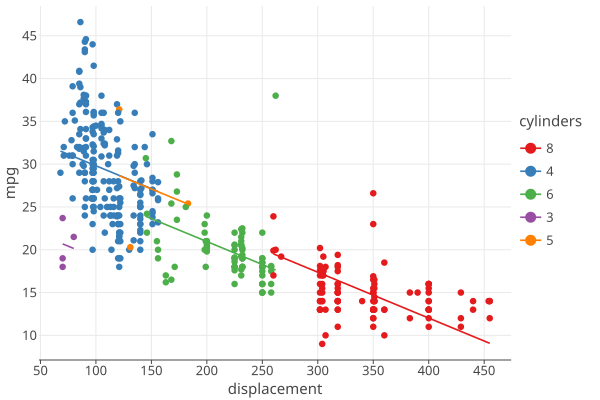

In [32]:
cars = cars.assign(pred=results.predict(cars))

(
    ggplot(data=cars)
    + geom_point(mapping=aes(x='displacement', y='mpg', color=as_discrete('cylinders')))
    + geom_line(mapping=aes(x='displacement', y='pred', color=as_discrete('cylinders')))
    + ylab('mpg')
)

# Part 9 - Slide 60

Consider the `auto_mpg.data.original` dataset
* Build a linear model to predict mpg given:
  
  $$\frac{1}{displacement^2}$$

In [33]:
cars9 = auto_mpg.data.original.copy()
cars9['inv_D2'] = 1 / cars9['displacement']**2

X = cars9[['inv_D2']]
y = cars9['mpg']

mpg_invD2_model = LinearRegression()
mpg_invD2_model.fit(X, y)
mpg_invD2_model.intercept_, *mpg_invD2_model.coef_

(np.float64(16.502808546271417), np.float64(123227.9612325492))

* What is the regression equation?

mpg = 16.5028 + 123227.9612 × (1 / displacement²)

* Plot the model predictions

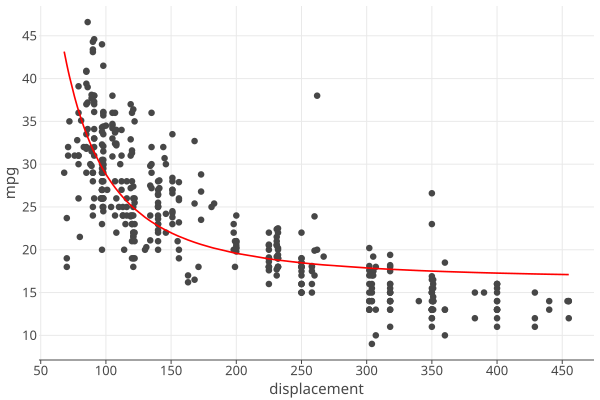

In [34]:
cars9['pred'] = mpg_invD2_model.predict(X)

(
    ggplot(data=cars9)
    + geom_point(mapping=aes(x='displacement', y='mpg'))
    + geom_line(mapping=aes(x='displacement', y='pred'), color='red')
    + ylab('mpg')
)